In [ ]:
#DEFINING GEOMETRY FOR THE VORTEX PANELS

import numpy as np

def define_panels(x, y):

    x = np.asarray([1, 0,  0, 1])
    y = np.asarray([0, 1, -1, 0])

    if x.ndim != 1 or y.ndim != 1:
        raise ValueError("x and y must be one-dimensional arrays.")

    if len(x) != len(y):
        raise ValueError("x and y must have the same length.")

    if len(x) < 4:
        raise ValueError("At least three panels are required for a closed contour.")

    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError("Coordinates must contain only finite values.")

    
    dx = np.diff(x)   # Has the output in an array
    dy = np.diff(y)
    
    length = np.hypot(dx, dy)   # Calculate individual panel lengths and put it in an array 
    if np.any(length <= 0.0):
        raise ValueError("There is an error in the panel calculation")

    
    theta = np.arctan2(dy, dx)  # Panel tangent angles in global coordinates
    theta_degrees = np.rad2deg(np.arctan2(dy, dx))   # arctan2() places the angle in the correct quadrant across the full circle
    
    
    x_control = 0.5 * (x[:-1] + x[1:])  # are the midpoints of the panel
    y_control = 0.5 * (y[:-1] + y[1:])

    
    tangent = np.column_stack((np.cos(theta),np.sin(theta)))  # Unit tangent vectors
    normal = np.column_stack((np.sin(theta),-np.cos(theta)))   # Outward unit normals
                                                               # for counterclockwise contour ordering
    
   
    # Signed polygon area: positive for counterclockwise ordering
    signed_area = 0.5 * np.sum(x[:-1] * y[1:] - x[1:] * y[:-1])

    if signed_area <= 0.0:
        raise ValueError("The contour must be ordered counterclockwise.")

    print(
        "x", x, "\n"
        "y", y, "\n"
        "length :", length, "\n"
        "theta : ", theta_degrees, "\n"
        "x_control : ", x_control, "\n"
        "y_control : ", y_control, "\n"
        "tangent :\n", tangent, "\n"
        "normal :\n", normal, "\n"
        "signed_area :", signed_area, "\n"
        "num_panels : ", len(length)
    )

define_panels(None, None)

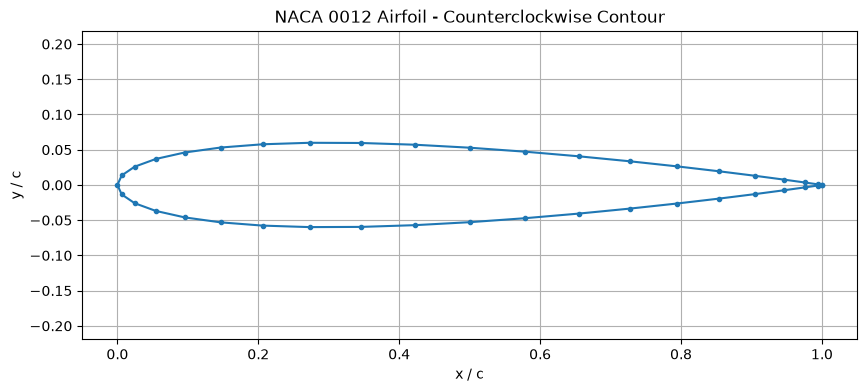

Number of surface nodes: 41
Number of panels: 40

x_coordinates of panels [1.         0.99384417 0.97552826 0.94550326 0.9045085  0.85355339
 0.79389263 0.72699525 0.6545085  0.57821723 0.5        0.42178277
 0.3454915  0.27300475 0.20610737 0.14644661 0.0954915  0.05449674
 0.02447174 0.00615583 0.         0.00615583 0.02447174 0.05449674
 0.0954915  0.14644661 0.20610737 0.27300475 0.3454915  0.42178277
 0.5        0.57821723 0.6545085  0.72699525 0.79389263 0.85355339
 0.9045085  0.94550326 0.97552826 0.99384417 1.        ]

y_coordinates of panels [-1.66533454e-17  8.91186344e-04  3.50136226e-03  7.65082165e-03
  1.30709457e-02  1.94384764e-02  2.64046500e-02  3.36104300e-02
  4.06861839e-02  4.72421489e-02  5.28615020e-02  5.71082323e-02
  5.95567645e-02  5.98411270e-02  5.77118565e-02  5.30826501e-02
  4.60488284e-02  3.68665348e-02  2.58933127e-02  1.35033681e-02
  0.00000000e+00 -1.35033681e-02 -2.58933127e-02 -3.68665348e-02
 -4.60488284e-02 -5.30826501e-02 -5.77118565e-02 -5.

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# NACA 0012 geometry
c = 1.0                 
t = 0.12                
n = 20                  

# Cosine spacing
beta = np.linspace(0.0, np.pi, n + 1)
x_dist = 0.5 * c * (1.0 - np.cos(beta))


yt = 5.0 * t * c * (
    0.2969 * np.sqrt(x_dist / c)
    - 0.1260 * (x_dist / c)
    - 0.3516 * (x_dist / c)**2
    + 0.2843 * (x_dist / c)**3
    - 0.1036 * (x_dist / c)**4)

# Upper and lower surface coordinates
x_upper = x_dist
y_upper = yt

x_lower = x_dist
y_lower = -yt

# Arrange contour counterclockwise:
x = np.concatenate((x_upper[::-1], x_lower[1:]))    # Stores them as a single long array in counterclockwise direction
y = np.concatenate((y_upper[::-1], y_lower[1:]))

# Plot the airfoil
plt.figure(figsize=(10, 4))
plt.plot(x, y, 'o-', markersize=3)
plt.xlabel("x / c")
plt.ylabel("y / c")
plt.title("NACA 0012 Airfoil - Counterclockwise Contour")
plt.axis("equal")
plt.grid(True)
plt.show()

print("Number of surface nodes:", len(x))
print("Number of panels:", len(x) - 1)
print("\nx_coordinates of panels", x)
print("\ny_coordinates of panels", y)
print("-" * 100)





        ################################################################################################################################



# DEFINING GEOMETRY FOR THE VORTEX PANELS

import numpy as np

def define_panels(x, y):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if x.ndim != 1 or y.ndim != 1:
        raise ValueError("x and y must be one-dimensional arrays.")

    if len(x) != len(y):
        raise ValueError("x and y must have the same length.")

    if len(x) < 4:
        raise ValueError("At least three panels are required for a closed contour.")

    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError("Coordinates must contain only finite values.")

    
    dx = np.diff(x)   # Has the output in an array
    dy = np.diff(y)
    
    length = np.hypot(dx, dy)   # Calculate individual panel lengths and put it in an array 
    if np.any(length <= 0.0):
        raise ValueError("There is an error in the panel calculation")

    
    theta = np.arctan2(dy, dx)   # Panel tangent angles in global coordinates
    theta_degrees = np.rad2deg(np.arctan2(dy, dx))    # arctan2() places the angle in the correct quadrant across the full circle
    
    
    x_control = 0.5 * (x[:-1] + x[1:])  # are the midpoints of the panel
    y_control = 0.5 * (y[:-1] + y[1:])

    
    tangent = np.column_stack((np.cos(theta),np.sin(theta)))   # Unit tangent vectors
    normal = np.column_stack((np.sin(theta),-np.cos(theta)))   # Outward unit normals
                                                               # for counterclockwise contour
    
   
    signed_area = 0.5 * np.sum(x[:-1] * y[1:] - x[1:] * y[:-1])  # Signed polygon area check - Shoelace formula

    if signed_area <= 0.0:
        raise ValueError("The contour must be ordered counterclockwise.")


    return {
        "x": x,
        "y": y,
        "length": length,
        "theta": theta,
        "x_control": x_control,
        "y_control": y_control,
        "tangent": tangent,
        "normal": normal,
        "signed_area": signed_area,
        "num_panels": len(length),
    }                                           # Storing them as dictionary

    
      
      ########################################################################################################################################



# IMPLEMENTING INFLUENCE INTEGRALS

def calculate_influence_integrals(panels):

    x = panels["x"]
    y = panels["y"]
    x_control = panels["x_control"]
    y_control = panels["y_control"]
    S = panels["length"]
    theta = panels["theta"]
    N = panels["num_panels"]

    I0_matrix = np.zeros((N, N))
    J0_matrix = np.zeros((N, N))
    I1_matrix = np.zeros((N, N))
    J1_matrix = np.zeros((N, N))

    # Loop over observation points
    for i in range(N):

        xc = x_control[i]
        yc = y_control[i]

        for j in range(N):

            Sj = S[j]
            theta_j = theta[j]

            dx = xc - x[j]    # Global coordinate differences
            dy = yc - y[j]

            x_local = dx*np.cos(theta_j) + dy*np.sin(theta_j)    # Global coordinate differences 
            y_local = -dx*np.sin(theta_j) + dy*np.cos(theta_j)

            if i == j:

                I0_matrix[i, j] = -np.pi
                J0_matrix[i, j] = 0.0
                I1_matrix[i, j] = -np.pi * Sj / 2.0
                J1_matrix[i, j] = -Sj / 2.0
                
            else:
                
                I0 = np.arctan2(y_local, x_local-Sj) - np.arctan2(y_local, x_local)
                                                                  
                numerator = x_local**2 + y_local**2
                denominator = (x_local-Sj)**2 + y_local**2
                J0 = 0.5*np.log(numerator/denominator)

                I1 = x_local*I0 - y_local*J0

                J1 = x_local*J0 - Sj + y_local*I0

                
                I0_matrix[i, j] = I0
                J0_matrix[i, j] = J0
                I1_matrix[i, j] = I1
                J1_matrix[i, j] = J1

    return I0_matrix, J0_matrix, I1_matrix, J1_matrix

panels = define_panels(x, y)
I0, J0, I1, J1 = calculate_influence_integrals(panels)

print("\nI0 matrix:\n", I0)
print("\nJ0 matrix:\n", J0)
print("\nI1 matrix:\n", I1)
print("\nJ1 matrix:\n", J1)

print("\nMatrix dimensions:")
print("I0:", I0.shape)
print("J0:", J0.shape)
print("I1:", I1.shape)
print("J1:", J1.shape)
print("-" * 100)



     ########################################################################################################################################



# DEFINING NORMAL AND TANGENTIAL MATRIX FOR BOUNDARY CONDITION CHECK

def calculate_influence_integralss(x, y, S):      # Redifining the function for code clarity
                                                  # Calculating only the off-diagolnal terms(1560 terms)
    I0 = np.arctan2(S * y, x * (x - S) + y**2)

    numerator = x**2 + y**2
    denominator = (x - S)**2 + y**2
    J0 = 0.5 * np.log(numerator / denominator)

    I1 = x * I0 - y * J0

    J1 = x * J0 - S + y * I0

    return I0, J0, I1, J1


def calculate_velocity_coefficients(panels):

    N = panels["num_panels"]
    x = panels["x"]
    y = panels["y"]
    xc = panels["x_control"]
    yc = panels["y_control"]
    length = panels["length"]
    theta = panels["theta"]

    # Matrices for normal and tangential influences
    A_normal = np.zeros((N, N + 1))
    T_tangent = np.zeros((N, N + 1))

    for i in range(N):

        # Observation point i
        for j in range(N):

            S = length[j]
            theta_j = theta[j]

            dx = xc[i] - x[j]
            dy = yc[i] - y[j]
            
            x_local = dx * np.cos(theta_j) + dy * np.sin(theta_j)    # Transform into source panel local coordinates
            y_local = -dx * np.sin(theta_j) + dy * np.cos(theta_j)

            # Self-influence coefficients
            if i == j:

                U_L = 1.0 / 4.0
                U_R = 1.0 / 4.0
                W_L = 1.0 / (2.0 * np.pi)
                W_R = -1.0 / (2.0 * np.pi)

            else:
                
                I0, J0, I1, J1 = calculate_influence_integralss(x_local, y_local, S)

                U_L = -(I0 - I1 / S) / (2.0 * np.pi)     # Local tangential velocity coefficients
                U_R = -I1 / (2.0 * np.pi * S)

                W_L = (J0 - J1 / S) / (2.0 * np.pi)      # Local positive-y velocity coefficients
                W_R = J1 / (2.0 * np.pi * S)
            
            delta = theta[i] - theta[j]     # Relative panel orientation(local and global)

            
            A_L = U_L * np.sin(delta) - W_L * np.cos(delta)    # Normal influence coefficients
            A_R = U_R * np.sin(delta) - W_R * np.cos(delta)

            
            T_L = U_L * np.cos(delta) + W_L * np.sin(delta)     # Tangential influence coefficients
            T_R = U_R * np.cos(delta) + W_R * np.sin(delta)

            
            A_normal[i, j] += A_L         # Store contributions at the two source-panel endpoints
            A_normal[i, j + 1] += A_R

            T_tangent[i, j] += T_L
            T_tangent[i, j + 1] += T_R

    return A_normal, T_tangent


panels = define_panels(x, y)

A_normal, T_tangent = calculate_velocity_coefficients(panels)

print("\nNormal influence matrix:")
print(A_normal)

print("\nTangential influence matrix:")
print(T_tangent)

print("\nDimensions:")
print("Normal size:", A_normal.shape)
print("Tangent size:", T_tangent.shape)
print("-" * 100)


      ########################################################################################################################################



# ASSEMBLING THE NORMAL COMPONENTS AND 1 KUTTA CONDITION IN MATRIX


print("\n'M' matrix contains all normal components and extra Kutta conditoin in last row")
print("'b' matrix contains all freestream velocity normal velocity components with Kutta condition in last row")

def assemble_linear_system(panels, A_normal, V_inf, alpha):

    N = panels["num_panels"]
    theta = panels["theta"]

    M = np.zeros((N + 1, N + 1))
    
    M[:N, :] = A_normal     # First N rows: no-penetration boundary condition
    
    M[N, 0] = 1.0      # Last row: Kutta condition
    M[N, N] = 1.0
    
    b = np.zeros(N + 1)    # RHS vector
    b[:N] = -V_inf * np.sin(theta - alpha)

    b[N] = 0.0       # Last RHS entry is zero for the Kutta condition

    return M, b


V_inf = 1.0
alpha_deg = 0.0
alpha = np.radians(alpha_deg)

M, b = assemble_linear_system(panels,A_normal,V_inf,alpha)

print("\nM:", M)
print("\nb:", b)


print("\nDimensions:")
print("M:", M.shape)
print("b:", b.shape)




# SOLVING THE MATRIX AND STORING VORTEX STRENGTHS IN MATRIX WITH KUTTA CONDITION

def solve_vortex_strengths(M, b):
    
    strength = np.linalg.solve(M, b)
    return strength

strength = solve_vortex_strengths(M, b)

print("\nNumber of unknowns/vortex strength:", len(strength))

print("\nNodal vortex strengths:")

for k in range(len(strength)):
    print(f"Node {k+1:2d}: strength = {strength[k]: .10f}")

print("-" * 100)


    ########################################################################################################################################





